# Explainable Stress Detection from Wearable Physiological Signals (WESAD)

An end-to-end, CPU-efficient physiological signal processing and explainable machine learning notebook using wrist-worn **Empatica E4** sensors from the **UCI WESAD Dataset** (`EDA` @ 4 Hz, `BVP` @ 64 Hz, `TEMP` @ 4 Hz, and 3-axis `ACC` @ 32 Hz).

### Notebook Workflow & Sections
* **Section 0: Environment Setup & Global Configuration** — Imports, deterministic random seeds, sensor sampling rates, and output directory setup.
* **Section 0.1: Automated Dataset Resolution (Local -> Google Drive -> UCI Download)** — Automatically locates existing WESAD `.pkl` files on local disk, checks/mounts Google Drive (`WESAD.zip` or `WESAD/` folder) if running in Colab, or downloads and extracts the archive directly from the UCI repository.
* **Section 1: Signal Loading, Alignment & Physiological Filtering** — Load subject `.pkl` files, align 700 Hz protocol labels (`1`: Baseline, `2`: Stress, `3`: Amusement) to wrist signals, apply zero-phase Butterworth filters, and plot raw traces with shaded condition bands (`300 DPI`).
* **Section 2: Windowing, Feature Extraction & Parquet Caching** — Slice signals into 60 s windows with a 30 s step ($\ge 80\%$ label purity), extract 19 physiological features via `neurokit2` and `numpy`, cache the feature table to Parquet, and plot feature distribution violin plots (`300 DPI`).
* **Section 3: Subject-Independent Modeling — Leave-One-Subject-Out (LOSO) vs. Random Split** — Train Logistic Regression, Random Forest, and XGBoost on Binary (Stress vs. Non-Stress) and 3-Class tasks. Compare subject-independent LOSO cross-validation against a 5-fold Stratified Random Split to quantify the subject data-leakage gap, and generate per-subject accuracy and confusion matrix figures (`300 DPI`).
* **Section 4: Explainability (SHAP) & Sensor Perturbation Robustness** — Compute global (`beeswarm`) and local (`waterfall`) SHAP explanations on the best tree model and run an additive Gaussian sensor noise stress-test ($\sigma \in [0.0, 1.0]$) (`300 DPI`).
* **Section 5: Link to VR Cybersickness Prediction & Perturbation Robustness** — Connect the extracted autonomic biomarkers, cold-start LOSO generalization, and noise sensitivity findings to Virtual Reality cybersickness forecasting.

---
## Section 0: Environment Setup & Global Configuration
Install required packages if needed and configure deterministic seeds, directory paths, and Empatica E4 sampling rates.

In [17]:
# Uncomment the line below to install dependencies if running in a fresh environment:
!pip install numpy pandas scipy neurokit2 scikit-learn xgboost shap matplotlib seaborn pyarrow

import os
import pickle
import shutil
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import neurokit2 as nk
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from scipy.signal import butter, filtfilt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Reproducibility seed
SEED = 42
np.random.seed(SEED)

# Directory paths
DATA_DIR = Path("./WESAD")
OUTPUT_DIR = Path("./outputs")
FIG_DIR = OUTPUT_DIR / "figures"
CACHE_FILE = OUTPUT_DIR / "wesad_wrist_features.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Sampling rates (Hz)
FS_LABEL = 700  # Chest/protocol ground-truth label sampling rate
FS_EDA = 4      # Wrist Electrodermal Activity
FS_BVP = 64     # Wrist Blood Volume Pulse (PPG)
FS_TEMP = 4     # Wrist Peripheral Skin Temperature
FS_ACC = 32     # Wrist 3-Axis Accelerometer

# Windowing configuration (seconds)
WIN_SEC = 60
STEP_SEC = 30
VALID_LABELS = {1: "Baseline", 2: "Stress", 3: "Amusement"}

print(f"Configuration initialized. Figures will be saved at 300 DPI to: {FIG_DIR.resolve()}")

Configuration initialized. Figures will be saved at 300 DPI to: /content/outputs/figures


---
## Section 0.1: Automated Dataset Resolution (Local Disk $\rightarrow$ Google Drive $\rightarrow$ Direct UCI Download)
This cell automatically locates or acquires the WESAD dataset using a 3-stage priority cascade:
1. **Priority 1 (Local Disk)**: Checks if `S*.pkl` files (or `WESAD.zip`) already exist locally in `./WESAD`.
2. **Priority 2 (Google Drive — Option 2)**: If running in Google Colab and local files are missing, mounts Google Drive and checks for either `MyDrive/WESAD.zip` (extracting it to local SSD for fast I/O) or an unzipped `MyDrive/WESAD/` folder.
3. **Priority 3 (UCI Direct Download — Option 1)**: If not found locally or on Google Drive, downloads the ~2 GB archive directly from the official UCI repository and extracts it to `./WESAD`.

In [18]:
import re
import shutil
import urllib.request
import zipfile
from pathlib import Path

# Official dataset pages and mirrors
SIEGEN_PAGE_URL = "https://ubi29.informatik.uni-siegen.de/usi/data_wesad.html"
KAGGLE_DATASET_HANDLE = "orvile/wesad-wearable-stress-affect-detection-dataset"
MIN_VALID_ZIP_BYTES = 100 * 1024 * 1024  # 100 MB minimum (real WESAD.zip is ~2.2 - 2.5 GB)


def _count_subject_pickles(directory: Path) -> list[Path]:
    """
    Recursively searches `directory` for WESAD subject pickle files (S2.pkl .. S17.pkl).
    Handles uppercase/lowercase ('S2.pkl' or 's2.pkl') and excludes macOS metadata ('._S*.pkl').
    """
    if not directory or not directory.exists():
        return []
    found = []
    for p in directory.rglob("*.pkl"):
        if p.name.startswith("._"):
            continue
        stem_upper = p.stem.upper()
        if stem_upper.startswith("S") and stem_upper[1:].isdigit():
            found.append(p)
    return sorted(found, key=lambda x: int(x.stem[1:]))


def _is_valid_wesad_zip(zip_path: Path) -> bool:
    """
    Verifies that a WESAD.zip file is the real multi-gigabyte archive (>100 MB)
    and NOT the tiny <1 KB UCI placeholder zip that only contains WESAD.txt.
    """
    if not zip_path.exists():
        return False
    size_bytes = zip_path.stat().st_size
    if size_bytes < MIN_VALID_ZIP_BYTES:
        print(
            f"[CLEANUP] Removing invalid/placeholder {zip_path} "
            f"({size_bytes / 1024:.1f} KB < 100 MB; only contains WESAD.txt)."
        )
        try:
            zip_path.unlink()
        except Exception as e:
            print(f"  -> Could not delete {zip_path}: {e}")
        return False
    return True


def _extract_zip(zip_path: Path, extract_to: Path):
    """
    Extracts a ZIP archive into `extract_to` and recursively unpacks any nested .zip files.
    """
    print(f"[EXTRACT] Unzipping {zip_path} ({zip_path.stat().st_size / (1024**3):.2f} GB) -> {extract_to.resolve()} ...")
    extract_to.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_to)

    for _ in range(3):
        nested_zips = [
            z for z in extract_to.rglob("*.zip")
            if not z.name.startswith("._") and z.resolve() != zip_path.resolve()
        ]
        if not nested_zips:
            break
        for nz in nested_zips:
            print(f"[EXTRACT: NESTED] Unpacking inner archive {nz.name} -> {nz.parent} ...")
            with zipfile.ZipFile(nz, "r") as nzf:
                nzf.extractall(nz.parent)
            nz.unlink()

    print("[EXTRACT] Extraction finished.")


def _download_with_progress(url: str, dest_path: Path):
    """
    Downloads a large file with a live console progress indicator.
    """
    print(f"[DOWNLOAD] Fetching WESAD archive from:\n  {url}")
    dest_path.parent.mkdir(parents=True, exist_ok=True)

    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as response, open(dest_path, "wb") as out_file:
        total_len = response.getheader("Content-Length")
        total_size = int(total_len) if total_len else -1
        block_size = 1024 * 1024  # 1 MB chunks
        downloaded = 0
        while True:
            chunk = response.read(block_size)
            if not chunk:
                break
            out_file.write(chunk)
            downloaded += len(chunk)
            mb_done = downloaded / (1024 * 1024)
            if total_size > 0:
                pct = min(100.0, downloaded * 100.0 / total_size)
                mb_total = total_size / (1024 * 1024)
                print(f"\r  -> Progress: {pct:5.1f}% ({mb_done:,.1f} / {mb_total:,.1f} MB)", end="", flush=True)
            else:
                print(f"\r  -> Downloaded: {mb_done:,.1f} MB", end="", flush=True)
    print("\n[DOWNLOAD] Download complete.")


def _resolve_siegen_direct_url(local_dir: Path) -> str | None:
    """
    Inspects local WESAD.txt (if present) or scrapes the University of Siegen WESAD page
    to find the direct 2.5 GB .zip download link.
    """
    # 1. Check if WESAD.txt is already in local_dir and print its contents for transparency
    wesad_txt = local_dir / "WESAD.txt"
    candidate_pages = [SIEGEN_PAGE_URL]
    if wesad_txt.exists():
        txt_content = wesad_txt.read_text(encoding="utf-8", errors="ignore")
        print(f"[INFO] Contents of UCI placeholder WESAD.txt:\n  {txt_content.strip()}")
        urls_in_txt = re.findall(r"https?://[^\s\"'>]+", txt_content)
        for u in urls_in_txt:
            if u.lower().endswith(".zip"):
                return u
            candidate_pages.insert(0, u)

    # 2. Scrape the University of Siegen page for the direct .zip link
    for page_url in candidate_pages:
        try:
            req = urllib.request.Request(page_url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=20) as resp:
                html = resp.read().decode("utf-8", errors="ignore")
            # Look for href="...WESAD.zip" or similar .zip link
            hrefs = re.findall(r'href=["\']([^"\']+\.zip[^"\']*)["\']', html, flags=re.IGNORECASE)
            for href in hrefs:
                full_url = urllib.parse.urljoin(page_url, href)
                return full_url
        except Exception as e:
            print(f"[WARN] Could not inspect {page_url}: {e}")
    return None


def resolve_wesad_dataset(
    local_dir: Path = Path("./WESAD"),
    drive_folder_rel: str = "MyDrive/WESAD",
    drive_zip_rel: str = "MyDrive/WESAD.zip",
    save_zip_to_drive: bool = True,
) -> Path:
    """
    Automatically locates or acquires the 15-subject WESAD dataset using a priority cascade:
      1. Local Disk (`local_dir` or valid >100MB `WESAD.zip`)
      2. Google Drive (`MyDrive/WESAD.zip` >100MB or `MyDrive/WESAD/` folder)
      3. Direct Download:
         - Option 1A: Fast KaggleHub mirror (`orvile/wesad-wearable-stress-affect-detection-dataset`)
         - Option 1B: Official University of Siegen direct `.zip` link (scraped from WESAD.txt / Siegen page)
    """
    # =========================================================================
    # PRIORITY 1: Check Local Disk First
    # =========================================================================
    local_pkls = _count_subject_pickles(local_dir)
    if local_pkls:
        print(f"[DATASET: LOCAL] Found {len(local_pkls)} subject pickle files in {local_dir.resolve()}.")
        return local_dir

    local_zip = local_dir.parent / "WESAD.zip"
    if _is_valid_wesad_zip(local_zip):
        print(f"[DATASET: LOCAL ZIP] Found valid archive at {local_zip.resolve()}.")
        _extract_zip(local_zip, local_dir)
        local_pkls = _count_subject_pickles(local_dir)
        if local_pkls:
            return local_dir

    # =========================================================================
    # PRIORITY 2: Check Google Drive (Option 2)
    # =========================================================================
    drive_mounted = False
    drive_root = Path("/content/drive")

    try:
        import google.colab  # type: ignore
        in_colab = True
    except ImportError:
        in_colab = False

    if in_colab:
        print("[DATASET: DRIVE] Checking Google Drive (Option 2)...")
        try:
            from google.colab import drive  # type: ignore
            if not (drive_root / "MyDrive").exists():
                drive.mount(str(drive_root))
            drive_mounted = (drive_root / "MyDrive").exists()
        except Exception as e:
            print(f"[DATASET: DRIVE] Google Drive mount skipped or failed ({e}).")
            drive_mounted = False

    if drive_mounted:
        drive_zip_path = drive_root / drive_zip_rel
        drive_folder_path = drive_root / drive_folder_rel

        # Verify that MyDrive/WESAD.zip is NOT the 1KB placeholder before extracting!
        if _is_valid_wesad_zip(drive_zip_path):
            print(f"[DATASET: DRIVE ZIP] Found valid archive on Drive at {drive_zip_path}.")
            _extract_zip(drive_zip_path, local_dir)
            local_pkls = _count_subject_pickles(local_dir)
            if local_pkls:
                print(f"[DATASET: DRIVE ZIP] Extracted {len(local_pkls)} subjects to {local_dir.resolve()}.")
                return local_dir

        drive_pkls = _count_subject_pickles(drive_folder_path)
        if drive_pkls:
            print(f"[DATASET: DRIVE FOLDER] Found {len(drive_pkls)} subjects on Drive at {drive_folder_path.resolve()}.")
            return drive_folder_path

    # =========================================================================
    # PRIORITY 3A: Download via KaggleHub Mirror (Fastest, pre-installed in Colab)
    # =========================================================================
    print("[DATASET: DOWNLOAD] Attempting fast download via `kagglehub` mirror...")
    try:
        import kagglehub  # type: ignore
        dl_path = Path(kagglehub.dataset_download(KAGGLE_DATASET_HANDLE))
        kh_pkls = _count_subject_pickles(dl_path)
        if kh_pkls:
            print(f"[DATASET: KAGGLEHUB] Downloaded {len(kh_pkls)} subject pickles to {dl_path.resolve()}.")
            # Optionally copy to Google Drive folder so future Colab sessions hit Priority 2B!
            if drive_mounted and save_zip_to_drive:
                drive_folder_path = drive_root / drive_folder_rel
                if not _count_subject_pickles(drive_folder_path):
                    print(f"[DATASET: BACKUP] Copying subject pickles to Google Drive ({drive_folder_path}) for future sessions...")
                    for pkl in kh_pkls:
                        subj_dest = drive_folder_path / pkl.stem.upper()
                        subj_dest.mkdir(parents=True, exist_ok=True)
                        shutil.copy2(pkl, subj_dest / f"{pkl.stem.upper()}.pkl")
            return dl_path
    except Exception as e:
        print(f"[WARN] `kagglehub` mirror failed ({e}). Trying University of Siegen direct download...")

    # =========================================================================
    # PRIORITY 3B: Direct Download from University of Siegen (Scraped from WESAD.txt)
    # =========================================================================
    siegen_zip_url = _resolve_siegen_direct_url(local_dir)
    if siegen_zip_url:
        print(f"[DATASET: SIEGEN] Found direct archive URL: {siegen_zip_url}")
        _download_with_progress(siegen_zip_url, local_zip)
        if _is_valid_wesad_zip(local_zip):
            if drive_mounted and save_zip_to_drive:
                drive_zip_dest = drive_root / drive_zip_rel
                print(f"[DATASET: BACKUP] Backing up valid WESAD.zip to Google Drive ({drive_zip_dest})...")
                shutil.copy2(local_zip, drive_zip_dest)
            _extract_zip(local_zip, local_dir)
            local_zip.unlink()

    final_pkls = _count_subject_pickles(local_dir)
    if not final_pkls:
        raise FileNotFoundError(
            f"Could not automatically download the 2.5 GB WESAD archive into {local_dir.resolve()}."
        )

    print(f"[DATASET: READY] {len(final_pkls)} subject pickle files ready at {local_dir.resolve()}:")
    print("  Subjects:", [p.name for p in final_pkls])
    return local_dir


# Execute the automatic dataset resolver and update DATA_DIR:
DATA_DIR = resolve_wesad_dataset(
    local_dir=DATA_DIR,
    drive_folder_rel="MyDrive/WESAD",
    drive_zip_rel="MyDrive/WESAD.zip",
    save_zip_to_drive=True,
)

[DATASET: DRIVE] Checking Google Drive (Option 2)...
[DATASET: DRIVE FOLDER] Found 15 subjects on Drive at /content/drive/MyDrive/WESAD.


---
## Section 1: Signal Loading, Alignment & Physiological Filtering
Each WESAD subject file (`S2.pkl` ... `S17.pkl`) stores wrist dictionary streams at their native sampling rates (`4 Hz`, `64 Hz`, `32 Hz`) alongside a `700 Hz` protocol label array. Because every stream starts synchronously at $t = 0$ and spans the exact same duration $T$, aligning any window $[t_{\text{start}}, t_{\text{end}}]$ in seconds maps directly to slice indices $[t_{\text{start}} \cdot f_s, t_{\text{end}} \cdot f_s]$ for each modality.

In [19]:
def butter_lowpass_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype="low", analog=False)
    return filtfilt(b, a, data, axis=0)


def butter_bandpass_filter(data, lowcut, highcut, fs, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype="band", analog=False)
    return filtfilt(b, a, data, axis=0)


def load_subject(pkl_path: Path) -> dict:
    """Loads a WESAD subject pickle and extracts wrist signals + 700 Hz protocol labels."""
    with open(pkl_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")
    wrist = data["signal"]["wrist"]
    labels = data["label"]  # 700 Hz
    return {
        "EDA": wrist["EDA"].flatten(),
        "BVP": wrist["BVP"].flatten(),
        "TEMP": wrist["TEMP"].flatten(),
        "ACC": wrist["ACC"],  # shape (N, 3)
        "label": labels.flatten(),
        "subject": pkl_path.stem,
    }


def preprocess_signals(subj_data: dict) -> dict:
    """Applies zero-phase Butterworth filtering to wrist EDA, BVP, and TEMP signals."""
    eda_filt = butter_lowpass_filter(subj_data["EDA"], cutoff=1.0, fs=FS_EDA, order=2)
    bvp_filt = butter_bandpass_filter(subj_data["BVP"], lowcut=0.5, highcut=8.0, fs=FS_BVP, order=3)
    temp_filt = butter_lowpass_filter(subj_data["TEMP"], cutoff=0.5, fs=FS_TEMP, order=2)

    return {
        "EDA": eda_filt,
        "BVP": bvp_filt,
        "TEMP": temp_filt,
        "ACC": subj_data["ACC"],
        "label": subj_data["label"],
        "subject": subj_data["subject"],
    }

### Step 1.1: Raw Wrist Traces with Shaded Condition Bands (300 DPI)
Plots filtered wrist `EDA`, `BVP`, and `TEMP` for a sample subject across the protocol timeline with shaded intervals for **Baseline**, **Stress**, and **Amusement**.

In [20]:
def plot_raw_signals(subj_data: dict, out_path: Path):
    """Figure 1: Raw EDA, BVP, and TEMP traces with shaded condition bands."""
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    total_sec = len(subj_data["label"]) / FS_LABEL

    t_eda = np.arange(len(subj_data["EDA"])) / FS_EDA
    t_bvp = np.arange(len(subj_data["BVP"])) / FS_BVP
    t_temp = np.arange(len(subj_data["TEMP"])) / FS_TEMP

    axes[0].plot(t_eda / 60, subj_data["EDA"], color="#1f77b4", lw=1.0)
    axes[0].set_ylabel("EDA ($\mu$S)", fontweight="bold")
    axes[0].set_title(f"Wrist Empatica E4 Physiological Traces — Subject {subj_data['subject']}", fontweight="bold")

    axes[1].plot(t_bvp[::4] / 60, subj_data["BVP"][::4], color="#d62728", lw=0.6)
    axes[1].set_ylabel("BVP (a.u.)", fontweight="bold")

    axes[2].plot(t_temp / 60, subj_data["TEMP"], color="#ff7f0e", lw=1.2)
    axes[2].set_ylabel("TEMP (°C)", fontweight="bold")
    axes[2].set_xlabel("Time (Minutes)", fontweight="bold")

    colors = {1: "#2ca02c", 2: "#d62728", 3: "#9467bd"}
    labels_1hz = subj_data["label"][::FS_LABEL]
    for cond_id, cond_name in VALID_LABELS.items():
        mask = labels_1hz == cond_id
        if not np.any(mask):
            continue
        diff = np.diff(mask.astype(int), prepend=0, append=0)
        starts = np.where(diff == 1)[0]
        ends = np.where(diff == -1)[0]
        for s, e in zip(starts, ends):
            for ax in axes:
                ax.axvspan(s / 60, e / 60, color=colors[cond_id], alpha=0.18, lw=0)

    patches = [mpatches.Patch(color=colors[k], alpha=0.35, label=v) for k, v in VALID_LABELS.items()]
    axes[0].legend(handles=patches, loc="upper right", frameon=True)
    plt.xlim(0, total_sec / 60)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved: {out_path}")

---
## Section 2: Windowing (60 s / 30 s Step), Feature Extraction & Parquet Caching
We segment each subject's synchronized streams into **60-second windows** with a **30-second step** (50% overlap), retaining windows where at least 80% of the 700 Hz samples belong to a single target condition (`1`: Baseline, `2`: Stress, `3`: Amusement).

For each window, we extract **19 physiological and kinematic features**:
* **EDA (7 features)**: Tonic SCL mean/std, Phasic driver mean/std, SCR peak count, SCR mean amplitude (`neurokit2`), and linear tonic drift slope (`numpy`).
* **BVP / HRV (6 features)**: Mean/std Heart Rate (BPM) and time-domain HRV metrics (`HRV_RMSSD`, `HRV_SDNN`, `HRV_pNN50`, `HRV_MeanNN`) via `neurokit2.ppg_process` and `neurokit2.hrv_time`.
* **TEMP (5 features)**: Mean, std, min, max, and peripheral vasoconstriction/vasodilation linear slope (°C/s).
* **ACC (4 features)**: 3D Euclidean magnitude mean, std, interquartile range (IQR), and mean temporal jerk.

In [21]:
def extract_window_features(eda_w, bvp_w, temp_w, acc_w) -> dict:
    """Extracts EDA, BVP/HRV, TEMP, and ACC features for a single 60s window."""
    feats = {}

    # --- 1. EDA Features (4 Hz) ---
    try:
        eda_signals, eda_info = nk.eda_process(eda_w, sampling_rate=FS_EDA, method="neurokit")
        tonic = eda_signals["EDA_Tonic"].values
        phasic = eda_signals["EDA_Phasic"].values
        peaks = eda_signals["SCR_Peaks"].values
        amps = eda_signals["SCR_Amplitude"].values

        feats["eda_tonic_mean"] = float(np.nanmean(tonic))
        feats["eda_tonic_std"] = float(np.nanstd(tonic))
        feats["eda_phasic_mean"] = float(np.nanmean(phasic))
        feats["eda_phasic_std"] = float(np.nanstd(phasic))
        feats["eda_scr_count"] = float(np.nansum(peaks))
        valid_amps = amps[peaks == 1]
        feats["eda_scr_amp_mean"] = float(np.nanmean(valid_amps)) if len(valid_amps) > 0 else 0.0
    except Exception:
        feats["eda_tonic_mean"] = float(np.mean(eda_w))
        feats["eda_tonic_std"] = float(np.std(eda_w))
        feats["eda_phasic_mean"] = 0.0
        feats["eda_phasic_std"] = float(np.std(np.diff(eda_w)))
        feats["eda_scr_count"] = 0.0
        feats["eda_scr_amp_mean"] = 0.0

    feats["eda_slope"] = float(np.polyfit(np.arange(len(eda_w)), eda_w, 1)[0])

    # --- 2. BVP / HRV Features (64 Hz) ---
    try:
        ppg_signals, ppg_info = nk.ppg_process(bvp_w, sampling_rate=FS_BVP)
        hr = ppg_signals["PPG_Rate"].values
        feats["bvp_hr_mean"] = float(np.nanmean(hr))
        feats["bvp_hr_std"] = float(np.nanstd(hr))

        hrv_time = nk.hrv_time(ppg_info["PPG_Peaks"], sampling_rate=FS_BVP, show=False)
        feats["hrv_rmssd"] = float(hrv_time["HRV_RMSSD"].iloc[0])
        feats["hrv_sdnn"] = float(hrv_time["HRV_SDNN"].iloc[0])
        feats["hrv_pnn50"] = float(hrv_time["HRV_pNN50"].iloc[0])
        feats["hrv_mean_nn"] = float(hrv_time["HRV_MeanNN"].iloc[0])
    except Exception:
        feats["bvp_hr_mean"] = np.nan
        feats["bvp_hr_std"] = np.nan
        feats["hrv_rmssd"] = np.nan
        feats["hrv_sdnn"] = np.nan
        feats["hrv_pnn50"] = np.nan
        feats["hrv_mean_nn"] = np.nan

    # --- 3. TEMP Features (4 Hz) ---
    t_idx = np.arange(len(temp_w)) / FS_TEMP
    feats["temp_mean"] = float(np.mean(temp_w))
    feats["temp_std"] = float(np.std(temp_w))
    feats["temp_min"] = float(np.min(temp_w))
    feats["temp_max"] = float(np.max(temp_w))
    feats["temp_slope"] = float(np.polyfit(t_idx, temp_w, 1)[0])

    # --- 4. ACC Features (32 Hz, 3-axis) ---
    acc_mag = np.linalg.norm(acc_w, axis=1)
    feats["acc_mag_mean"] = float(np.mean(acc_mag))
    feats["acc_mag_std"] = float(np.std(acc_mag))
    feats["acc_mag_iqr"] = float(np.percentile(acc_mag, 75) - np.percentile(acc_mag, 25))
    feats["acc_jerk_mean"] = float(np.mean(np.abs(np.diff(acc_mag) * FS_ACC)))

    return feats


def build_subject_windows(subj_data: dict) -> pd.DataFrame:
    """Slices aligned wrist signals into 60s windows with 30s step."""
    total_sec = int(len(subj_data["label"]) // FS_LABEL)
    rows = []

    for start_sec in range(0, total_sec - WIN_SEC + 1, STEP_SEC):
        end_sec = start_sec + WIN_SEC

        lbl_seg = subj_data["label"][start_sec * FS_LABEL : end_sec * FS_LABEL]
        vals, counts = np.unique(lbl_seg, return_counts=True)
        maj_label = int(vals[np.argmax(counts)])
        purity = np.max(counts) / len(lbl_seg)

        if maj_label not in VALID_LABELS or purity < 0.80:
            continue

        eda_w = subj_data["EDA"][start_sec * FS_EDA : end_sec * FS_EDA]
        bvp_w = subj_data["BVP"][start_sec * FS_BVP : end_sec * FS_BVP]
        temp_w = subj_data["TEMP"][start_sec * FS_TEMP : end_sec * FS_TEMP]
        acc_w = subj_data["ACC"][start_sec * FS_ACC : end_sec * FS_ACC]

        feats = extract_window_features(eda_w, bvp_w, temp_w, acc_w)
        feats["subject"] = subj_data["subject"]
        feats["start_sec"] = start_sec
        feats["label_3class"] = maj_label
        feats["condition"] = VALID_LABELS[maj_label]
        feats["label_binary"] = 1 if maj_label == 2 else 0  # 1 = Stress, 0 = Non-Stress
        rows.append(feats)

    return pd.DataFrame(rows)


def get_or_build_dataset(data_dir: Path, cache_file: Path) -> tuple[pd.DataFrame, dict]:
    """Loads cached Parquet table or resolves/builds it from WESAD subject pickles."""
    pkl_files = _count_subject_pickles(data_dir)
    if not pkl_files:
        data_dir = resolve_wesad_dataset(local_dir=data_dir)
        pkl_files = _count_subject_pickles(data_dir)

    sample_subj_raw = preprocess_signals(load_subject(pkl_files[0]))

    if cache_file.exists():
        print(f"[INFO] Loading cached feature table from {cache_file}")
        df = pd.read_parquet(cache_file)
        return df, sample_subj_raw

    print(f"[INFO] Processing {len(pkl_files)} subjects from {data_dir}...")
    all_dfs = []
    for pkl in pkl_files:
        print(f"  -> Extracting features for {pkl.stem}...")
        raw = load_subject(pkl)
        filt = preprocess_signals(raw)
        df_subj = build_subject_windows(filt)
        all_dfs.append(df_subj)

    df = pd.concat(all_dfs, ignore_index=True)
    df.to_parquet(cache_file, index=False)
    print(f"[INFO] Saved {len(df)} windows across {df['subject'].nunique()} subjects to {cache_file}")
    return df, sample_subj_raw

### Step 2.1: Execute Feature Pipeline & Generate Raw Trace + Violin Plots

[INFO] Processing 15 subjects from /content/drive/MyDrive/WESAD...
  -> Extracting features for S2...
  -> Extracting features for S3...
  -> Extracting features for S4...
  -> Extracting features for S5...
  -> Extracting features for S6...
  -> Extracting features for S7...
  -> Extracting features for S8...
  -> Extracting features for S9...
  -> Extracting features for S10...
  -> Extracting features for S11...
  -> Extracting features for S13...
  -> Extracting features for S14...
  -> Extracting features for S15...
  -> Extracting features for S16...
  -> Extracting features for S17...
[INFO] Saved 1049 windows across 15 subjects to outputs/wesad_wrist_features.parquet
Dataset shape: (1049, 27)


,eda_tonic_mean,eda_tonic_std,eda_phasic_mean,eda_phasic_std,eda_scr_count,eda_scr_amp_mean,eda_slope,bvp_hr_mean,bvp_hr_std,hrv_rmssd,...,temp_slope,acc_mag_mean,acc_mag_std,acc_mag_iqr,acc_jerk_mean,subject,start_sec,label_3class,condition,label_binary
0,1.323711,0.131885,-0.003708,0.088676,13.0,0.156156,-0.001619,84.100763,27.424689,321.089431,...,-0.000727,63.755175,6.734675,3.639838,127.408503,S2,300,1,Baseline,0
1,1.115826,0.126480,-0.002416,0.062256,9.0,0.134456,-0.001630,77.882332,25.047428,312.842928,...,-0.002784,63.628972,5.437794,1.826292,91.828217,S2,330,1,Baseline,0
2,0.889345,0.150765,-0.000208,0.011893,7.0,0.026310,-0.002144,76.142187,22.224158,290.840068,...,-0.000544,63.297968,2.231543,1.138751,38.973529,S2,360,1,Baseline,0
3,0.701587,0.075926,-0.000042,0.006649,10.0,0.013036,-0.001097,77.608895,23.232856,284.092013,...,0.001563,63.455554,1.416786,0.710282,25.663856,S2,390,1,Baseline,0
4,0.581129,0.066775,0.000015,0.009317,8.0,0.021763,-0.000962,76.555880,17.609529,179.498952,...,0.002149,63.599109,4.058449,0.748578,60.926485,S2,420,1,Baseline,0


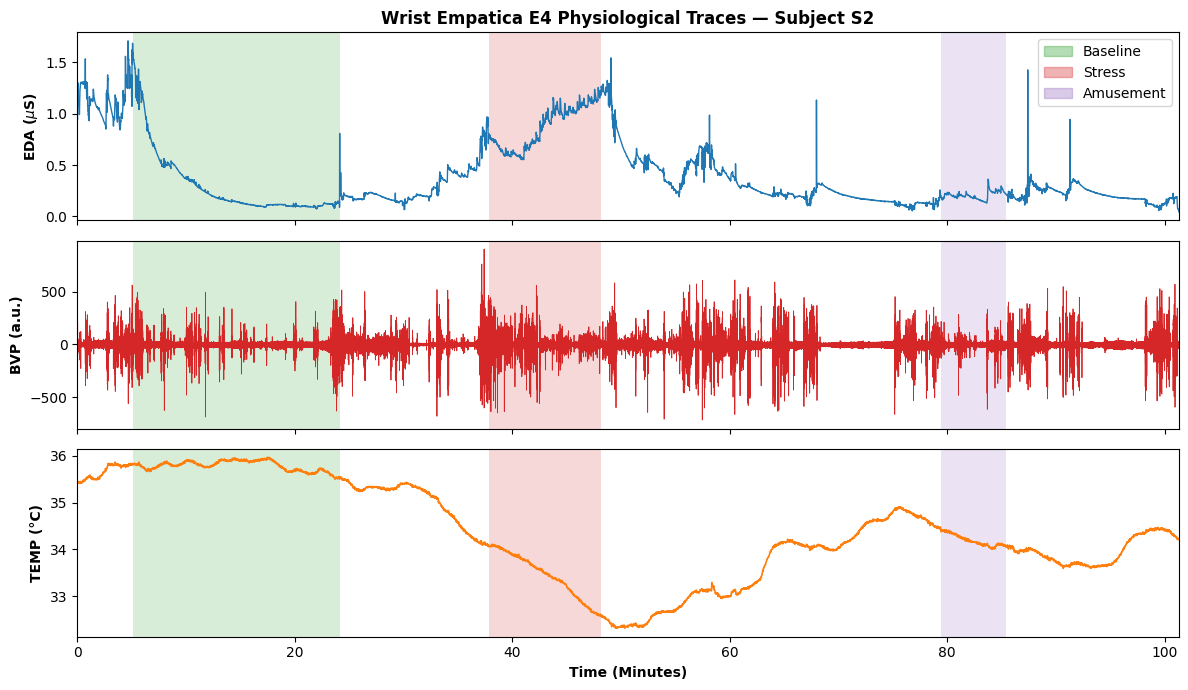

Saved: outputs/figures/01_raw_signals_condition_bands.png


In [22]:
df, sample_subj_raw = get_or_build_dataset(DATA_DIR, CACHE_FILE)
print(f"Dataset shape: {df.shape}")
display(df.head())

# Plot Figure 1: Raw signals with shaded condition bands
plot_raw_signals(sample_subj_raw, FIG_DIR / "01_raw_signals_condition_bands.png")

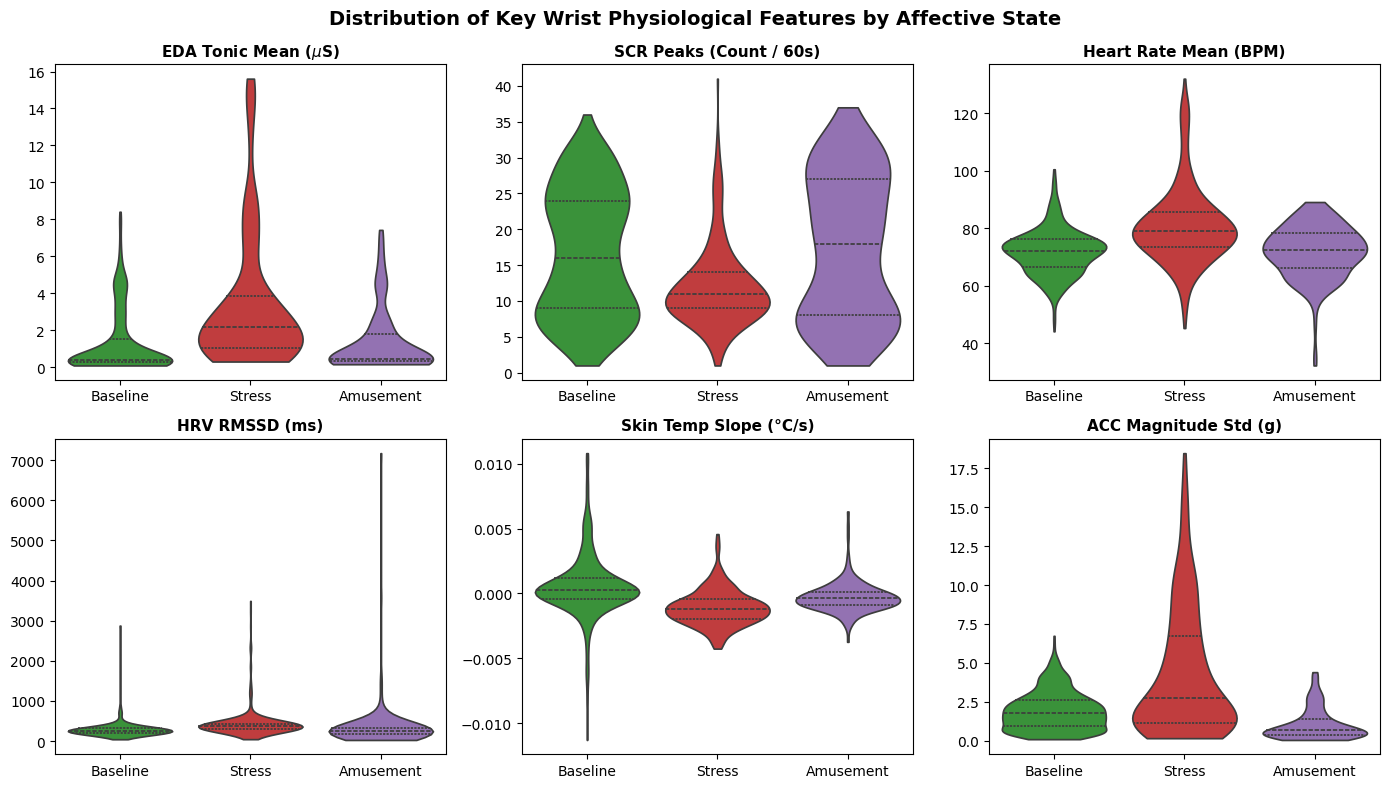

Saved: outputs/figures/02_feature_violin_plots.png


In [23]:
def plot_feature_violins(df: pd.DataFrame, out_path: Path):
    """Figure 2: Violin plots of top physiological features across conditions."""
    top_feats = [
        ("eda_tonic_mean", "EDA Tonic Mean ($\mu$S)"),
        ("eda_scr_count", "SCR Peaks (Count / 60s)"),
        ("bvp_hr_mean", "Heart Rate Mean (BPM)"),
        ("hrv_rmssd", "HRV RMSSD (ms)"),
        ("temp_slope", "Skin Temp Slope (°C/s)"),
        ("acc_mag_std", "ACC Magnitude Std (g)"),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    palette = {"Baseline": "#2ca02c", "Stress": "#d62728", "Amusement": "#9467bd"}

    for ax, (col, title) in zip(axes.flat, top_feats):
        sns.violinplot(
            data=df, x="condition", y=col, order=["Baseline", "Stress", "Amusement"],
            palette=palette, inner="quartile", cut=0, ax=ax
        )
        ax.set_title(title, fontweight="bold", fontsize=11)
        ax.set_xlabel("")
        ax.set_ylabel("")

    plt.suptitle("Distribution of Key Wrist Physiological Features by Affective State", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved: {out_path}")

plot_feature_violins(df, FIG_DIR / "02_feature_violin_plots.png")

---
## Section 3: Subject-Independent Modeling — Leave-One-Subject-Out (LOSO) vs. Random Split
We compare **Logistic Regression**, **Random Forest**, and **XGBoost** across two classification tasks:
1. **Binary Task**: Stress (`1`) vs. Non-Stress (`0`, combining Baseline and Amusement).
2. **3-Class Task**: Baseline (`1`) vs. Stress (`2`) vs. Amusement (`3`).

Each model is evaluated under two cross-validation schemes:
* **Leave-One-Subject-Out (LOSO) CV**: Trains on $N-1$ subjects and evaluates on the unseen held-out subject.
* **5-Fold Stratified Random Split**: Randomly shuffles 60-second windows across train and test folds, illustrating how overlapping windows from the same subject cause optimistic data leakage.

In [24]:
def get_models():
    return {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", RandomForestClassifier(
                n_estimators=200, max_depth=8, class_weight="balanced", random_state=SEED, n_jobs=-1
            )),
        ]),
        "XGBoost": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", XGBClassifier(
                n_estimators=150,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=SEED,
                n_jobs=-1,
            )),
        ]),
    }


def evaluate_loso_and_random(df: pd.DataFrame, feature_cols: list, target_col: str):
    """Runs Leave-One-Subject-Out (LOSO) CV and 5-fold Stratified Random Split CV."""
    X = df[feature_cols].values
    y = df[target_col].values
    unique_labels = np.sort(np.unique(y))
    label_map = {val: idx for idx, val in enumerate(unique_labels)}
    y_mapped = np.array([label_map[val] for val in y])
    groups = df["subject"].values

    logo = LeaveOneGroupOut()
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    models = get_models()

    results = {}
    for name, pipeline in models.items():
        # 1. LOSO Evaluation
        loso_preds = np.zeros_like(y_mapped)
        subj_metrics = []
        for train_idx, test_idx in logo.split(X, y_mapped, groups):
            pipeline.fit(X[train_idx], y_mapped[train_idx])
            preds = pipeline.predict(X[test_idx])
            loso_preds[test_idx] = preds
            subj_id = groups[test_idx][0]
            subj_metrics.append({
                "subject": subj_id,
                "accuracy": accuracy_score(y_mapped[test_idx], preds),
                "f1_macro": f1_score(y_mapped[test_idx], preds, average="macro", zero_division=0),
            })

        loso_acc = accuracy_score(y_mapped, loso_preds)
        loso_f1 = f1_score(y_mapped, loso_preds, average="macro")

        # 2. Random Split Evaluation (shows data leakage from same-subject windows)
        rand_preds = np.zeros_like(y_mapped)
        for train_idx, test_idx in skf.split(X, y_mapped):
            pipeline.fit(X[train_idx], y_mapped[train_idx])
            rand_preds[test_idx] = pipeline.predict(X[test_idx])

        rand_acc = accuracy_score(y_mapped, rand_preds)
        rand_f1 = f1_score(y_mapped, rand_preds, average="macro")

        results[name] = {
            "loso_acc": loso_acc,
            "loso_f1": loso_f1,
            "rand_acc": rand_acc,
            "rand_f1": rand_f1,
            "loso_preds": loso_preds,
            "y_true": y_mapped,
            "per_subject": pd.DataFrame(subj_metrics),
        }

    return results

In [25]:
feature_cols = [
    c for c in df.columns
    if c not in ["subject", "start_sec", "label_3class", "condition", "label_binary"]
]

print("Evaluating Binary Task (Stress vs Non-Stress)...")
res_bin = evaluate_loso_and_random(df, feature_cols, "label_binary")
for m, r in res_bin.items():
    print(f"  {m:20s} | LOSO Acc: {r['loso_acc']*100:.2f}% (Macro F1: {r['loso_f1']*100:.2f}%) | Random Split Acc: {r['rand_acc']*100:.2f}%")

print("\nEvaluating 3-Class Task (Baseline vs Stress vs Amusement)...")
res_3c = evaluate_loso_and_random(df, feature_cols, "label_3class")
for m, r in res_3c.items():
    print(f"  {m:20s} | LOSO Acc: {r['loso_acc']*100:.2f}% (Macro F1: {r['loso_f1']*100:.2f}%) | Random Split Acc: {r['rand_acc']*100:.2f}%")

best_model = max(res_bin.keys(), key=lambda k: res_bin[k]["loso_acc"])
print(f"\nSelected Best Binary LOSO Model: {best_model}")

Evaluating Binary Task (Stress vs Non-Stress)...
  Logistic Regression  | LOSO Acc: 88.47% (Macro F1: 86.81%) | Random Split Acc: 92.56%
  Random Forest        | LOSO Acc: 91.61% (Macro F1: 89.71%) | Random Split Acc: 96.85%
  XGBoost              | LOSO Acc: 91.13% (Macro F1: 89.20%) | Random Split Acc: 97.71%

Evaluating 3-Class Task (Baseline vs Stress vs Amusement)...
  Logistic Regression  | LOSO Acc: 71.02% (Macro F1: 67.44%) | Random Split Acc: 78.17%
  Random Forest        | LOSO Acc: 76.17% (Macro F1: 64.85%) | Random Split Acc: 92.09%
  XGBoost              | LOSO Acc: 79.03% (Macro F1: 70.03%) | Random Split Acc: 93.90%

Selected Best Binary LOSO Model: Random Forest


### Step 3.1: Per-Subject LOSO Accuracy, Leakage Gap & Confusion Matrices (300 DPI)

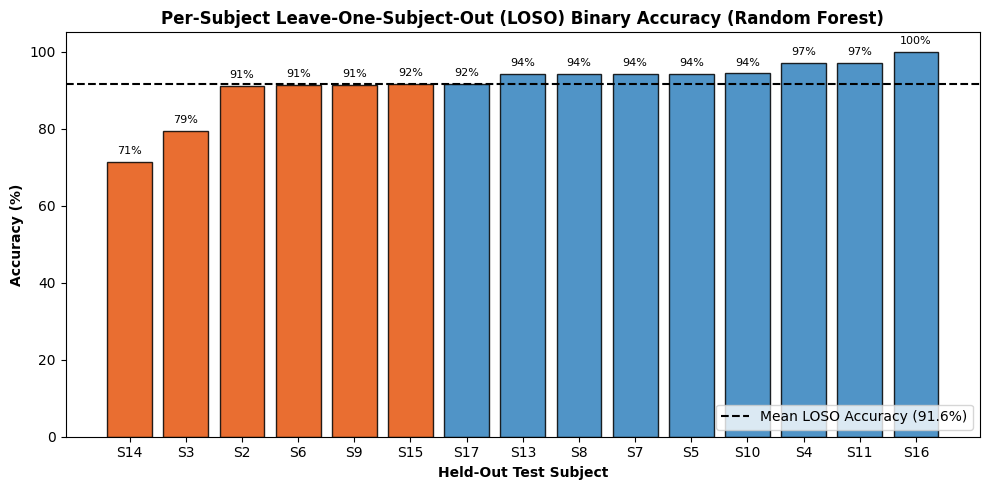

Saved: outputs/figures/03_loso_per_subject_accuracy.png


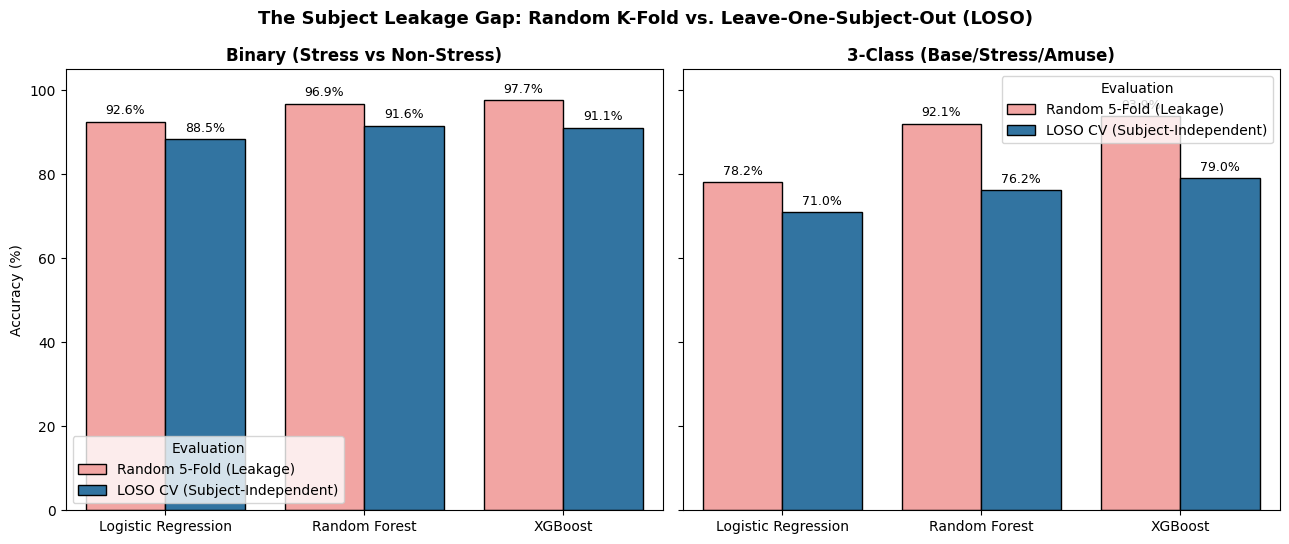

Saved: outputs/figures/04_loso_vs_random_leakage_gap.png


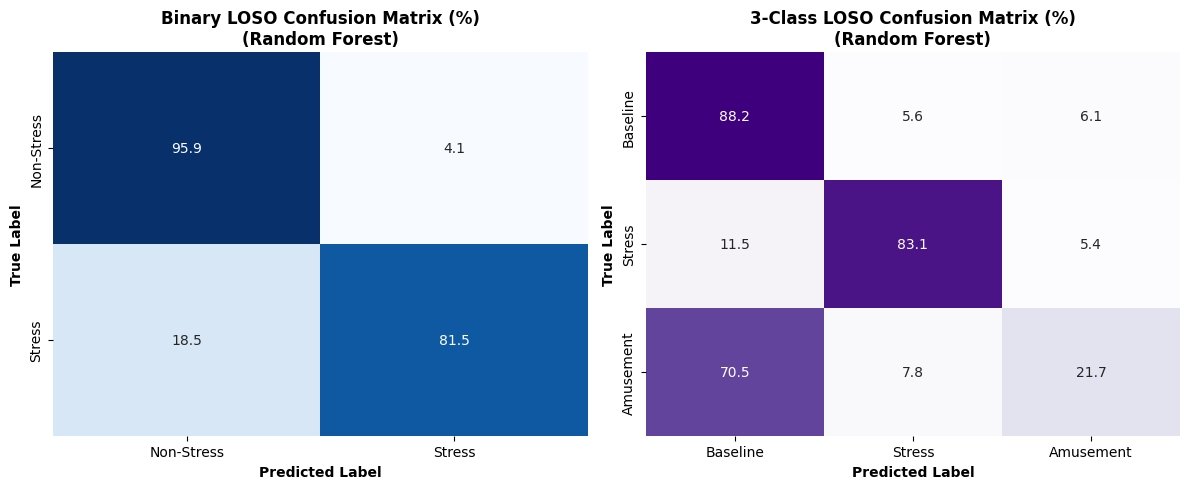

Saved: outputs/figures/05_confusion_matrices.png


In [26]:
def plot_per_subject_loso(per_subj_df: pd.DataFrame, model_name: str, out_path: Path):
    """Figure 3: Per-subject LOSO accuracy bar chart."""
    df_sorted = per_subj_df.sort_values("accuracy", ascending=True)
    mean_acc = df_sorted["accuracy"].mean()

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(
        df_sorted["subject"], df_sorted["accuracy"] * 100,
        color=np.where(df_sorted["accuracy"] < mean_acc, "#e6550d", "#3182bd"),
        edgecolor="black", alpha=0.85
    )
    ax.axhline(mean_acc * 100, color="black", linestyle="--", lw=1.5, label=f"Mean LOSO Accuracy ({mean_acc*100:.1f}%)")
    ax.set_ylim(0, 105)
    ax.set_ylabel("Accuracy (%)", fontweight="bold")
    ax.set_xlabel("Held-Out Test Subject", fontweight="bold")
    ax.set_title(f"Per-Subject Leave-One-Subject-Out (LOSO) Binary Accuracy ({model_name})", fontweight="bold")
    ax.legend(loc="lower right")

    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1.5, f"{h:.0f}%", ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved: {out_path}")


def plot_loso_vs_random(res_bin: dict, res_3c: dict, out_path: Path):
    """Figure 4: Random split vs LOSO comparison illustrating the data leakage gap."""
    rows = []
    for task_label, res_dict in [("Binary (Stress vs Non-Stress)", res_bin), ("3-Class (Base/Stress/Amuse)", res_3c)]:
        for model_name, metrics in res_dict.items():
            rows.append({"Task": task_label, "Model": model_name, "Evaluation": "Random 5-Fold (Leakage)", "Accuracy": metrics["rand_acc"] * 100})
            rows.append({"Task": task_label, "Model": model_name, "Evaluation": "LOSO CV (Subject-Independent)", "Accuracy": metrics["loso_acc"] * 100})

    plot_df = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

    for ax, task_label in zip(axes, ["Binary (Stress vs Non-Stress)", "3-Class (Base/Stress/Amuse)"]):
        sub = plot_df[plot_df["Task"] == task_label]
        sns.barplot(
            data=sub, x="Model", y="Accuracy", hue="Evaluation",
            palette=["#ff9896", "#1f77b4"], edgecolor="black", ax=ax
        )
        ax.set_title(task_label, fontweight="bold")
        ax.set_ylim(0, 105)
        ax.set_xlabel("")
        ax.set_ylabel("Accuracy (%)" if ax == axes[0] else "")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

    plt.suptitle("The Subject Leakage Gap: Random K-Fold vs. Leave-One-Subject-Out (LOSO)", fontweight="bold", fontsize=13)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved: {out_path}")


def plot_confusion_matrices(res_bin: dict, res_3c: dict, best_model: str, out_path: Path):
    """Figure 5: Confusion matrices for binary and 3-class LOSO predictions."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    cm_bin = confusion_matrix(res_bin[best_model]["y_true"], res_bin[best_model]["loso_preds"], normalize="true")
    sns.heatmap(
        cm_bin * 100, annot=True, fmt=".1f", cmap="Blues", cbar=False,
        xticklabels=["Non-Stress", "Stress"], yticklabels=["Non-Stress", "Stress"], ax=axes[0]
    )
    axes[0].set_title(f"Binary LOSO Confusion Matrix (%)\n({best_model})", fontweight="bold")
    axes[0].set_xlabel("Predicted Label", fontweight="bold")
    axes[0].set_ylabel("True Label", fontweight="bold")

    cm_3c = confusion_matrix(res_3c[best_model]["y_true"], res_3c[best_model]["loso_preds"], normalize="true")
    sns.heatmap(
        cm_3c * 100, annot=True, fmt=".1f", cmap="Purples", cbar=False,
        xticklabels=["Baseline", "Stress", "Amusement"], yticklabels=["Baseline", "Stress", "Amusement"], ax=axes[1]
    )
    axes[1].set_title(f"3-Class LOSO Confusion Matrix (%)\n({best_model})", fontweight="bold")
    axes[1].set_xlabel("Predicted Label", fontweight="bold")
    axes[1].set_ylabel("True Label", fontweight="bold")

    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved: {out_path}")


plot_per_subject_loso(res_bin[best_model]["per_subject"], best_model, FIG_DIR / "03_loso_per_subject_accuracy.png")
plot_loso_vs_random(res_bin, res_3c, FIG_DIR / "04_loso_vs_random_leakage_gap.png")
plot_confusion_matrices(res_bin, res_3c, best_model, FIG_DIR / "05_confusion_matrices.png")

---
## Section 4: Explainability (SHAP) & Sensor Perturbation Robustness
We inspect global feature attributions (`shap.plots.beeswarm`) and single-prediction local attributions (`shap.plots.waterfall`), then evaluate classifier degradation under escalating Gaussian sensor noise ($\sigma \in [0.0, 1.0]$ scaled by training feature standard deviations).

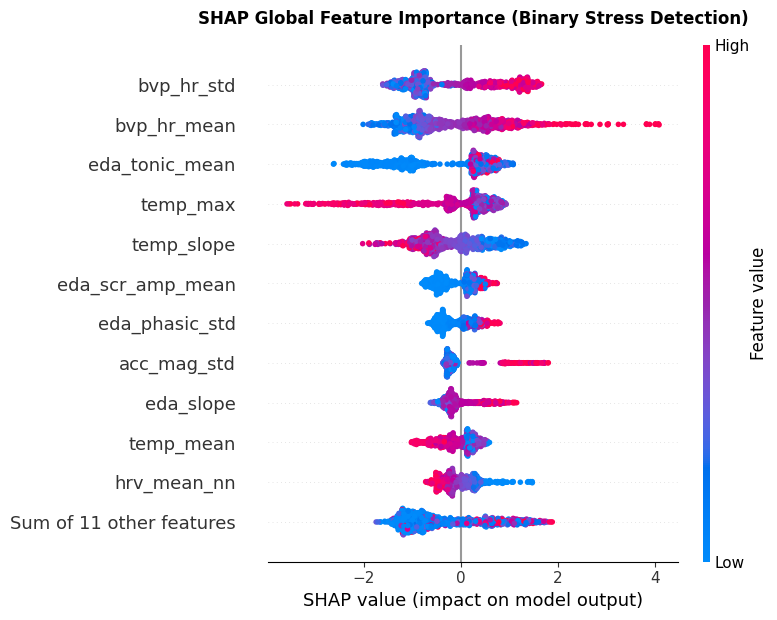

Saved: outputs/figures/06a_shap_beeswarm.png


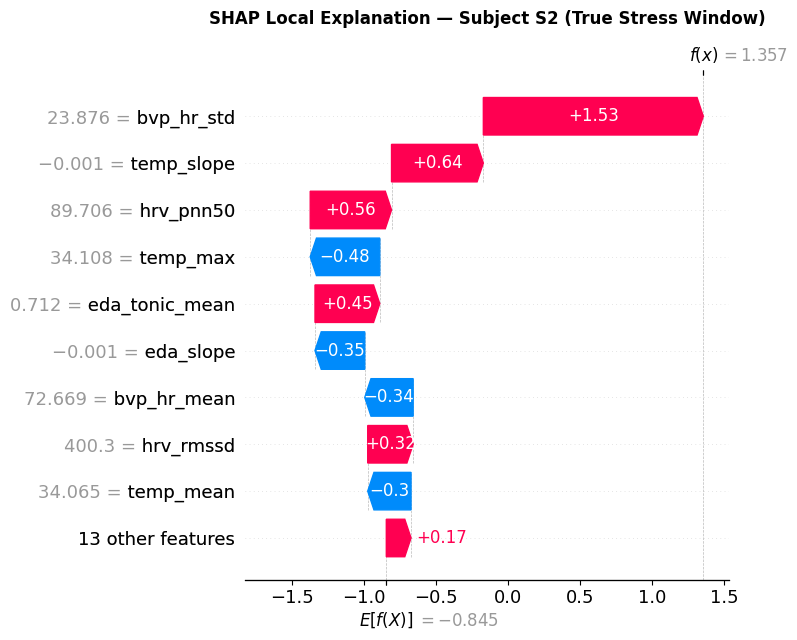

Saved: outputs/figures/06b_shap_waterfall.png


In [27]:
def plot_shap_explanations(df: pd.DataFrame, feature_cols: list, beeswarm_path: Path, waterfall_path: Path):
    """Figure 6a & 6b: Global SHAP beeswarm and local single-window SHAP waterfall."""
    X_raw = df[feature_cols].copy()
    y_bin = df["label_binary"].values

    imputer = SimpleImputer(strategy="median")
    X_imp = pd.DataFrame(imputer.fit_transform(X_raw), columns=feature_cols)

    xgb = XGBClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=SEED
    )
    xgb.fit(X_imp, y_bin)

    explainer = shap.TreeExplainer(xgb)
    shap_values = explainer(X_imp)

    # 6a. Global Beeswarm
    plt.figure(figsize=(10, 6))
    shap.plots.beeswarm(shap_values, max_display=12, show=False)
    plt.title("SHAP Global Feature Importance (Binary Stress Detection)", fontweight="bold", pad=15)
    plt.tight_layout()
    plt.savefig(beeswarm_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {beeswarm_path}")

    # 6b. Local Waterfall for a true Stress window
    stress_indices = np.where(y_bin == 1)[0]
    sample_idx = stress_indices[0]
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values[sample_idx], max_display=10, show=False)
    plt.title(f"SHAP Local Explanation — Subject {df.iloc[sample_idx]['subject']} (True Stress Window)", fontweight="bold", pad=15)
    plt.tight_layout()
    plt.savefig(waterfall_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {waterfall_path}")

plot_shap_explanations(
    df, feature_cols,
    FIG_DIR / "06a_shap_beeswarm.png",
    FIG_DIR / "06b_shap_waterfall.png"
)

### Step 4.1: Additive Gaussian Sensor Noise Stress-Test (300 DPI)

,noise_sigma,accuracy,f1_macro
0,0.00,0.916111,0.897088
1,0.05,0.917064,0.898963
2,0.10,0.918017,0.899019
3,0.20,0.900858,0.875824
4,0.35,0.868446,0.829168
5,0.50,0.851287,0.803575
6,0.75,0.832221,0.769563
7,1.00,0.798856,0.715421


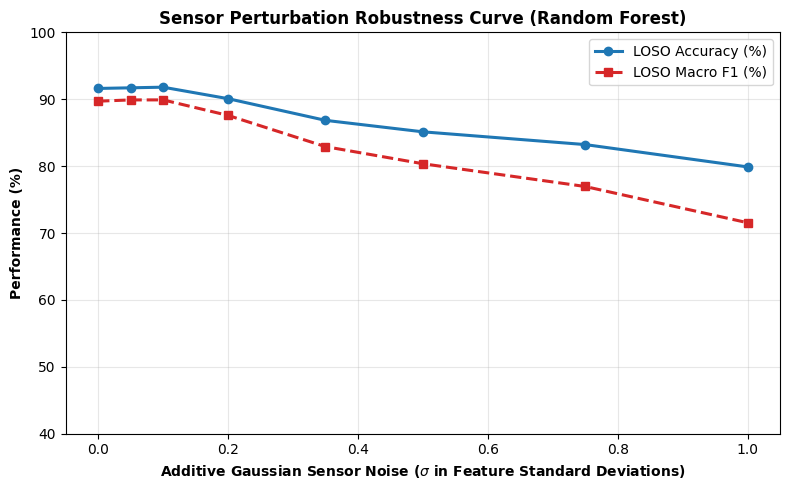

Saved: outputs/figures/07_noise_robustness_curve.png


In [28]:
def run_noise_robustness(df: pd.DataFrame, feature_cols: list, target_col: str, best_model_name: str):
    """Evaluates LOSO accuracy & macro-F1 across increasing Gaussian sensor noise levels."""
    X = df[feature_cols].values
    y = df[target_col].values
    unique_labels = np.sort(np.unique(y))
    label_map = {val: idx for idx, val in enumerate(unique_labels)}
    y_mapped = np.array([label_map[val] for val in y])
    groups = df["subject"].values

    noise_sigmas = [0.0, 0.05, 0.10, 0.20, 0.35, 0.50, 0.75, 1.00]
    logo = LeaveOneGroupOut()
    rng = np.random.default_rng(SEED)

    curve_rows = []
    for sigma in noise_sigmas:
        preds_all = np.zeros_like(y_mapped)
        for train_idx, test_idx in logo.split(X, y_mapped, groups):
            pipe = get_models()[best_model_name]
            pipe.fit(X[train_idx], y_mapped[train_idx])

            X_test_raw = X[test_idx].copy()
            feat_stds = np.nanstd(X[train_idx], axis=0)
            noise = rng.normal(loc=0.0, scale=sigma * feat_stds, size=X_test_raw.shape)
            X_test_noisy = X_test_raw + noise
            preds_all[test_idx] = pipe.predict(X_test_noisy)

        curve_rows.append({
            "noise_sigma": sigma,
            "accuracy": accuracy_score(y_mapped, preds_all),
            "f1_macro": f1_score(y_mapped, preds_all, average="macro"),
        })

    return pd.DataFrame(curve_rows)


def plot_noise_robustness(noise_df: pd.DataFrame, best_model: str, out_path: Path):
    """Figure 7: Accuracy & Macro F1 vs Gaussian noise perturbation level."""
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(noise_df["noise_sigma"], noise_df["accuracy"] * 100, marker="o", lw=2.2, color="#1f77b4", label="LOSO Accuracy (%)")
    ax.plot(noise_df["noise_sigma"], noise_df["f1_macro"] * 100, marker="s", lw=2.2, color="#d62728", linestyle="--", label="LOSO Macro F1 (%)")
    ax.set_xlabel("Additive Gaussian Sensor Noise ($\sigma$ in Feature Standard Deviations)", fontweight="bold")
    ax.set_ylabel("Performance (%)", fontweight="bold")
    ax.set_title(f"Sensor Perturbation Robustness Curve ({best_model})", fontweight="bold")
    ax.set_ylim(40, 100)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved: {out_path}")

noise_df = run_noise_robustness(df, feature_cols, "label_binary", best_model)
display(noise_df)
plot_noise_robustness(noise_df, best_model, FIG_DIR / "07_noise_robustness_curve.png")

---
## Section 5: Link to VR Cybersickness Prediction & Universal Adversarial Perturbations (UAP)
* **Shared Autonomic Pathways**: Visually induced motion sickness (cybersickness) in Virtual Reality triggers sympathetic sudomotor activation (`eda_tonic_mean`, `eda_scr_count`), peripheral vasoconstriction (`temp_slope`), and vagal withdrawal (`hrv_rmssd`)—the exact physiological signatures isolated by our SHAP analysis.
* **Cold-Start Generalization**: Commercial VR headsets cannot require new users to undergo sickness calibration sessions before gameplay. Evaluating models strictly under **Leave-One-Subject-Out (LOSO)** cross-validation reflects cold-start generalization to unseen VR users.
* **Motion Artifacts & Perturbation Robustness**: Active 6-DoF VR gameplay introduces wrist movement artifacts into PPG/EDA streams. Auditing feature sensitivity under additive Gaussian noise ($\sigma \in [0.0, 1.0]$) serves as a direct baseline for evaluating **Universal Adversarial Perturbations (UAPs)** on multimodal physiological time series.